# AI Bank Pricing Engine Walkthrough

Welcome. This notebook teaches you how to use the AI Bank Pricing Engine from the ground up.

You do **not** need to understand every line of Python to use it. The notebook is designed in two layers:

- **Beginner layer:** read the plain-English notes, run each cell from top to bottom, and focus on the output tables.
- **Technical layer:** inspect the code, change assumptions, rerun scenarios, and review model diagnostics.

The project uses **synthetic data only**. It currently recommends one portfolio-level home loan rate and one portfolio-level term deposit rate. It does **not** do personalized customer pricing.

## How To Use This Notebook

If you are new to Jupyter notebooks, use this simple routine:

1. Click the first code cell.
2. Press **Shift + Enter** to run it.
3. Read the output directly below the cell.
4. Move to the next cell and repeat.
5. Do not edit code until you reach the **Try Your Own Scenario** section.

### Recommended Beginner Path

For your first run, focus on these parts:

- **Data steps:** setup, assumptions, synthetic customers, and rate grids.
- **Pricing model steps:** baseline optimisation, winning decision, diagnostics, and sensitivity.
- **Response modelling steps:** optional model training diagnostics for synthetic observed outcomes.
- **Governed modelling steps:** optional champion/challenger training, registry, and scoring checks.
- **Optional inputs and next steps:** competitor-rate files, glossary, troubleshooting, and commands.

The governed modelling part is useful when you want to understand the recent model-risk workflow additions, but the core portfolio-pricing run is complete before that section.


## 0. Before You Start

The notebook assumes the project has already been installed into your Python environment.

From a terminal, run these commands once:

```bash
cd /Users/kevinchang/Documents/ai-bank-pricing-engine
/opt/homebrew/bin/python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip setuptools wheel
python -m pip install -e ".[dev]"
python -m ipykernel install --user --name ai-bank-pricing-engine-py312 --display-name "AI Bank Pricing Engine (Python 3.12)"
```

If `/opt/homebrew/bin/python3.12` does not exist on your machine, use `python3 -m venv .venv` instead.

Then launch Jupyter:

```bash
python -m notebook
```

Open this file:

```text
notebooks/bank_pricing_engine_walkthrough.ipynb
```

In VS Code or Jupyter, select this kernel if prompted:

```text
AI Bank Pricing Engine (Python 3.12)
```

### What Success Looks Like

A normal first run should eventually show:

- a **Best pricing decision** table,
- a **Top pricing candidates** table,
- a **Sensitivity analysis** table,
- response-model diagnostics,
- and governed modelling artifacts in `data/outputs/agentic_notebook/` if you run the optional governed section.

If you get an error, do not panic. The troubleshooting section near the end covers the common ones.


## The Big Picture In One Minute

The engine tests many possible pairs of rates:

```text
home loan rate + term deposit rate
```

For each pair, it estimates:

- how many synthetic home loan customers accept the loan rate,
- how many synthetic term deposit customers take up the deposit rate,
- how much income the bank earns on loans,
- how much credit loss the bank expects,
- how much interest the bank pays on deposits,
- whether deposits are enough to fund lending,
- and whether a funding shortfall penalty applies.

The engine then picks the pair with the highest total economic objective.

## Notebook Workflow
The notebook is now organised as a simple modelling workflow:

| Part | What you do | Why it matters |
|---|---|---|
| **Data steps** | Load assumptions, generate synthetic customers, inspect customer profiles, and build candidate rate grids. | These cells define the portfolio and pricing inputs. |
| **Pricing model steps** | Run the optimiser, inspect the winner, review the objective, check boundaries, and run sensitivity tests. | These cells explain the recommended portfolio-level rates. |
| **Response modelling steps** | Build synthetic response datasets, train simple models, and check calibration plus rate-response direction. | These cells show how learned response models can be evaluated before production use. |
| **Governed modelling steps** | Compare baseline and logistic candidates, write local lineage records, and score a sample with fallback controls. | These cells demonstrate the recent champion/challenger and model-governance additions. |
| **Optional inputs** | Try competitor-rate files and decide where to experiment next. | These cells connect the baseline workflow to future scenarios. |

Run the notebook from top to bottom the first time. After that, use the part headings to rerun the section you are exploring.



## Part 1: Data Steps
This part prepares the inputs used by the pricing engine. Nothing has been optimised yet; the goal is to understand the assumptions, synthetic customer data, and candidate rate grids.


### Data Step 1: Imports And Project Setup
Run the next two code cells first. They load Python packages and project functions used later.

**Beginner note:** if these cells run without an error, your notebook can see the project code.


In [1]:
from __future__ import annotations

from pathlib import Path
import sys

import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "configs" / "base.yaml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/kevinchang/Documents/ai-bank-pricing-engine


In [2]:
from balance_pricing_engine.config import load_config
from balance_pricing_engine.diagnostics import run_sensitivity_analysis
from balance_pricing_engine.modelling import (
    DEPOSIT_FEATURE_COLUMNS,
    DEPOSIT_TARGET_COLUMN,
    LOAN_FEATURE_COLUMNS,
    LOAN_TARGET_COLUMN,
    ModelRegistry,
    ModelScoringAgent,
    ModelTrainingAgent,
    TrainingConfig,
)
from balance_pricing_engine.modelling.workflows import run_response_model_workflow
from balance_pricing_engine.plotting import (
    plot_customer_profiles,
    plot_customer_relationships,
    plot_governed_modelling_summary,
    plot_rate_grid_story,
    plot_response_dataset_overview,
    plot_volume_and_funding_story,
    plot_workflow_map,
    plot_grid_search_results,
    plot_objective_decomposition,
    plot_response_model_report,
    plot_sensitivity_summary,
)
from balance_pricing_engine.rate_grids import build_configured_rate_grids
from balance_pricing_engine.reporting import (
    build_best_by_deposit_rate_table,
    build_best_by_loan_rate_table,
    build_best_decision_table,
    build_config_summary,
    build_customer_profile_tables,
    build_objective_decomposition_table,
    build_rate_grid_table,
    build_scenario_comparison_table,
    build_sensitivity_change_table,
    build_sensitivity_summary_table,
    format_result_table,
    fmt_money,
    fmt_rate,
)
from balance_pricing_engine.scenarios.experiments import run_higher_funding_penalty_scenario
from balance_pricing_engine.scenarios.runner import run_baseline_diagnostics
from balance_pricing_engine.synthetic.customers import (
    generate_deposit_customers,
    generate_loan_customers,
)
from balance_pricing_engine.utils.random import make_rng

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)


### If The Import Cell Fails

Common fixes:

- If you see `Running cells with 'Python 3.12.13' requires the ipykernel package`, install the notebook dependencies with `python -m pip install -e ".[dev]"` inside `.venv`, then run the `python -m ipykernel install ...` command from the setup section.
- If you see `ModuleNotFoundError: No module named 'balance_pricing_engine'`, install the project with `python -m pip install -e ".[dev]"` from the repo root.
- If you see a missing package like `sklearn`, rerun the install command above.
- If Jupyter is using the wrong Python environment, select the **AI Bank Pricing Engine (Python 3.12)** kernel or close Jupyter, activate `.venv`, and launch Jupyter again from the same terminal.


### Data Step 2: Formatting And Plotting Helpers
These helpers keep rates, dollar values, tables, and charts readable throughout the notebook.


In [3]:
# Formatting and table helpers are imported from balance_pricing_engine.reporting.
config = load_config(PROJECT_ROOT / "configs" / "base.yaml")

build_config_summary(config)


,section,section_explanation,assumption,value,assumption_explanation
0,simulation,Defines the size of the synthetic customer por...,loan customers,5000,Number of synthetic home loan customers used i...
1,simulation,Defines the size of the synthetic customer por...,deposit customers,5000,Number of synthetic term deposit customers use...
2,market,Sets the external interest-rate environment th...,cash rate,4.25%,Baseline central bank cash rate used as the st...
3,market,Sets the external interest-rate environment th...,wholesale funding spread,1.20%,Extra funding cost the bank pays above the cas...
4,market,Sets the external interest-rate environment th...,competitor loan rate,6.75%,"Typical home loan rate offered by competitors,..."
5,market,Sets the external interest-rate environment th...,competitor deposit rate,4.50%,Typical term deposit rate offered by competito...
6,market,Sets the external interest-rate environment th...,home loan reference rate,5.25%,Starting home loan rate before the strategy gr...
7,market,Sets the external interest-rate environment th...,term deposit reference rate,4.00%,Starting term deposit rate before the strategy...
8,balance sheet,Sets how the bank funds loans and how costly u...,required deposit funding ratio,65.00%,Minimum share of expected loans the bank wants...
9,balance sheet,Sets how the bank funds loans and how costly u...,funding shortfall penalty rate,1.80%,Penalty rate applied when expected deposits ar...


### Optional Plotting Helpers
These helpers keep the charts readable and make the notebook safe to run even when `matplotlib` is not installed.


In [4]:
# Chart helpers are imported from balance_pricing_engine.plotting.


### Visual Map: How The Pieces Fit Together
This picture is the beginner map for the whole notebook. Read it from left to right: assumptions create synthetic customers, the optimiser tests rates, diagnostics explain the answer, and modelling/governance checks sit around the pricing workflow.


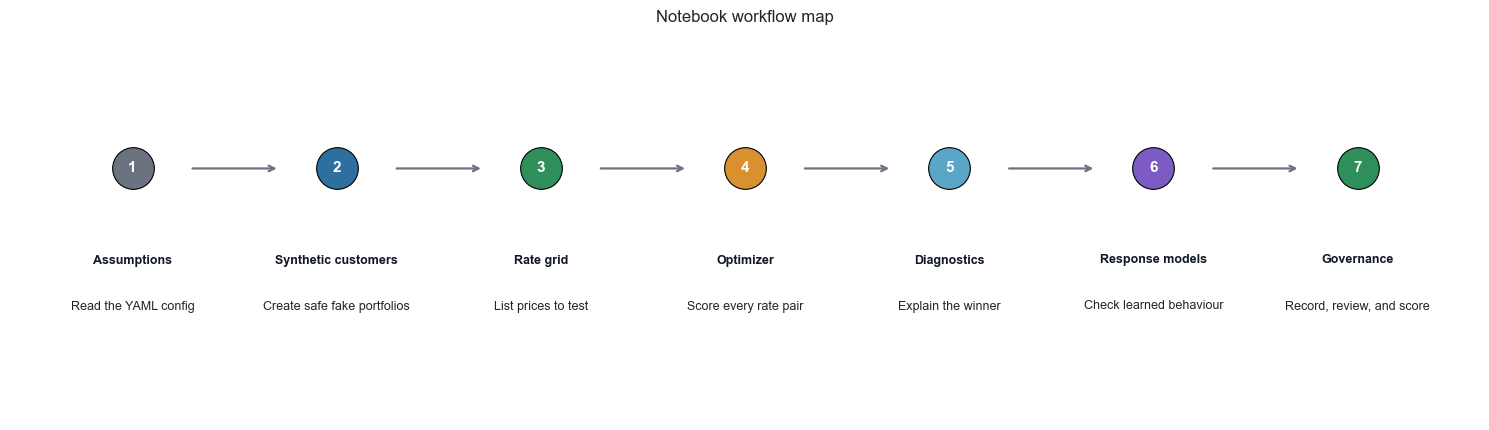

In [5]:
plot_workflow_map()


### Data Step 3: Load The Baseline Configuration
The baseline scenario lives in `configs/base.yaml`. Think of this file as the control panel for the model. It contains the market assumptions, simulation sizes, pricing ranges, balance-sheet settings, and random seed.


In [6]:
config_path = PROJECT_ROOT / "configs" / "base.yaml"
config = load_config(config_path)
config

EngineConfig(random_seed=42, simulation=SimulationConfig(n_loan_customers=5000, n_deposit_customers=5000), market=MarketConfig(cash_rate=0.0425, wholesale_funding_spread=0.012, competitor_loan_rate=0.0675, competitor_deposit_rate=0.045, home_loan_reference_rate=0.0525, term_deposit_reference_rate=0.04), products=None, pricing_strategy=PricingStrategyConfig(home_loan_spread_bps=SpreadGridConfigModel(min=-50.0, max=50.0, step=5.0), term_deposit_spread_bps=SpreadGridConfigModel(min=-40.0, max=40.0, step=5.0)), competitor_rates=CompetitorRatesConfig(enabled=False, source_file='data/processed/competitor_rates/latest.json', selected_banks=['ANZ', 'ASB', 'Westpac', 'BNZ', 'Kiwibank'], max_staleness_hours=48, strict=True, mortgage=MortgageStrategyConfig(strategy='market_average', bank=None, term_months=12, term_label=None, include_specials=True, require_min_20_percent_equity=True), term_deposit=TermDepositStrategyConfig(strategy='market_average', bank=None, term_months=12, product_type='term_d

In [7]:
config_summary = build_config_summary(config)
config_summary


,section,section_explanation,assumption,value,assumption_explanation
0,simulation,Defines the size of the synthetic customer por...,loan customers,5000,Number of synthetic home loan customers used i...
1,simulation,Defines the size of the synthetic customer por...,deposit customers,5000,Number of synthetic term deposit customers use...
2,market,Sets the external interest-rate environment th...,cash rate,4.25%,Baseline central bank cash rate used as the st...
3,market,Sets the external interest-rate environment th...,wholesale funding spread,1.20%,Extra funding cost the bank pays above the cas...
4,market,Sets the external interest-rate environment th...,competitor loan rate,6.75%,"Typical home loan rate offered by competitors,..."
5,market,Sets the external interest-rate environment th...,competitor deposit rate,4.50%,Typical term deposit rate offered by competito...
6,market,Sets the external interest-rate environment th...,home loan reference rate,5.25%,Starting home loan rate before the strategy gr...
7,market,Sets the external interest-rate environment th...,term deposit reference rate,4.00%,Starting term deposit rate before the strategy...
8,balance sheet,Sets how the bank funds loans and how costly u...,required deposit funding ratio,65.00%,Minimum share of expected loans the bank wants...
9,balance sheet,Sets how the bank funds loans and how costly u...,funding shortfall penalty rate,1.80%,Penalty rate applied when expected deposits ar...


### Response Coefficients: Config-Driven Elasticity

`config.response.coefficients` stores the config-driven response model coefficients used by the synthetic elasticity functions. It contains `LoanResponseCoefficientsConfig` and `DepositResponseCoefficientsConfig`, keeping the behavioural assumptions visible alongside the rate elasticities.

Loan coefficients: `intercept=1.10`, `rate_anchor=0.065`, `risk_score_coef=-1.20`, `credit_score_coef=0.35`, `lvr_coef=-0.25`.

Deposit coefficients: `intercept=-0.65`, `rate_anchor=0.045`, `rate_sensitivity_coef=0.60`, `relationship_coef=0.04`, `digital_coef=-0.20`.


In [8]:
import pandas as pd

loan_coefs = config.response.coefficients.loan.model_dump()
deposit_coefs = config.response.coefficients.deposit.model_dump()
coef_df = pd.DataFrame([{"product": "loan", **loan_coefs}, {"product": "deposit", **deposit_coefs}])
display(coef_df)


,product,intercept,rate_anchor,risk_score_coef,credit_score_coef,lvr_coef,rate_sensitivity_coef,relationship_coef,digital_coef
0,loan,1.10,0.065,-1.2,0.35,-0.25,NaN,NaN,NaN
1,deposit,-0.65,0.045,NaN,NaN,NaN,0.6,0.04,-0.2


In [9]:
modified_cfg = config.model_copy(
    update={
        "response": config.response.model_copy(
            update={"loan_rate_elasticity": config.response.loan_rate_elasticity * 1.25}
        )
    }
)
from balance_pricing_engine.scenarios.runner import run_baseline_diagnostics

baseline_diag_for_elasticity = run_baseline_diagnostics(config)
modified_diag = run_baseline_diagnostics(modified_cfg)
from balance_pricing_engine.reporting import build_scenario_comparison_table

display(build_scenario_comparison_table(baseline_diag_for_elasticity.best_result, modified_diag.best_result))


,scenario,loan_rate,deposit_rate,objective_value,expected_loan_volume,expected_deposit_volume,funding_shortfall
0,baseline,0.0800,0.0515,1.249639e+07,6.048198e+08,3.939366e+08,0.000000e+00
1,higher funding penalty,0.0785,0.0505,1.141185e+07,5.772660e+08,3.738238e+08,1.399085e+06


### What To Look For In The Assumptions Table

Start with these rows:

- **competitor loan rate:** the market loan rate the synthetic borrowers compare against.
- **competitor deposit rate:** the market deposit rate the synthetic deposit customers compare against.
- **required deposit funding ratio:** the share of lending management wants funded by deposits.
- **loan rate elasticity:** how strongly loan demand reacts when the offered loan rate changes.
- **deposit rate elasticity:** how strongly deposit uptake reacts when the offered deposit rate changes.

You do not need to memorize these. The important thing is that these assumptions drive the recommendation.

### Plain-English Interpretation

The engine is trying to choose one **home loan rate** and one **term deposit rate** for the whole synthetic portfolio.

The objective is:

```text
loan interest income
- expected credit loss
- deposit interest cost
- wholesale funding cost
- funding shortfall penalty
```

The best rate pair is the one with the highest total objective among all tested rate combinations.

### Data Step 4: Generate Synthetic Customers
The project does not use real customer data. It generates synthetic customers so you can test the pricing logic safely.

There are two synthetic portfolios:
- home-loan customers, representing potential lending demand
- term-deposit customers, representing potential funding supply


In [10]:
rng = make_rng(config.random_seed)
loan_customers = generate_loan_customers(config.simulation.n_loan_customers, rng)
deposit_customers = generate_deposit_customers(config.simulation.n_deposit_customers, rng)

print(f"Loan customers: {len(loan_customers):,}")
print(f"Deposit customers: {len(deposit_customers):,}")

Loan customers: 5,000
Deposit customers: 5,000


In [11]:
loan_customers.head()

,customer_id,product,loan_amount,credit_score,lvr,income,risk_score,expected_loss_rate
0,L000000,home_loan,4.129570e+05,731.330196,0.817973,68780.064932,0.529482,0.008890
1,L000001,home_loan,4.703451e+05,637.201113,0.942886,221938.222256,0.695210,0.012320
2,L000002,home_loan,8.432679e+05,762.531584,0.518797,277129.005498,0.233597,0.003850
3,L000003,home_loan,1.093284e+06,775.839530,0.572768,180951.238068,0.297611,0.004799
4,L000004,home_loan,7.983701e+05,573.427537,0.777814,128316.724325,0.751095,0.013557


In [12]:
deposit_customers.head()

,customer_id,product,deposit_amount,relationship_years,digital_engagement,rate_sensitivity
0,D000000,term_deposit,81468.495906,2.479390,0.308541,0.559100
1,D000001,term_deposit,68374.271258,1.148262,0.220074,0.498860
2,D000002,term_deposit,128898.653786,3.458247,0.592115,0.483139
3,D000003,term_deposit,60740.653160,7.233089,0.417288,0.616697
4,D000004,term_deposit,48322.553346,2.385424,0.482309,0.334071


### Beginner Data Dictionary

Useful home-loan columns:

- `loan_amount`: synthetic requested loan balance.
- `credit_score`: synthetic credit score.
- `lvr`: loan-to-value ratio. Higher values usually mean more risk.
- `income`: synthetic borrower income.
- `risk_score`: model-created risk indicator from 0 to 1.
- `expected_loss_rate`: expected annual credit loss rate.

Useful term-deposit columns:

- `deposit_amount`: synthetic deposit balance.
- `relationship_years`: synthetic customer tenure.
- `digital_engagement`: synthetic digital activity score.
- `rate_sensitivity`: how strongly the customer reacts to deposit rates.

In [13]:
loan_customer_profile, deposit_customer_profile = build_customer_profile_tables(
    loan_customers,
    deposit_customers,
)

loan_customer_profile


,count,mean,std,min,25%,50%,75%,max
loan_amount,5000.0,587328.837797,215131.093734,163594.547045,433457.761331,552284.468912,702614.085022,1.500000e+06
credit_score,5000.0,708.005899,68.440923,500.000000,661.563219,709.708730,754.187320,8.500000e+02
lvr,5000.0,0.721049,0.147600,0.450000,0.610669,0.733943,0.842206,9.800000e-01
income,5000.0,157345.806941,65255.929779,45000.000000,110875.783038,144973.817719,189857.332781,5.000000e+05
risk_score,5000.0,0.467248,0.146554,0.036725,0.365078,0.467486,0.567120,9.158029e-01
expected_loss_rate,5000.0,0.007878,0.002706,0.001676,0.005891,0.007708,0.009636,1.741458e-02


In [14]:
deposit_customer_profile

,count,mean,std,min,25%,50%,75%,max
deposit_amount,5000.0,111297.409803,95902.843962,5722.628449,50742.929000,83256.252122,138801.133614,1000000.000000
relationship_years,5000.0,4.920470,3.081842,0.040441,2.639573,4.258675,6.563632,28.602888
digital_engagement,5000.0,0.444206,0.209455,0.005305,0.283592,0.435299,0.594441,0.995222
rate_sensitivity,5000.0,0.546019,0.177572,0.050000,0.427460,0.544184,0.670283,0.950000


### Customer Profile Charts
These charts give you a quick visual feel for the synthetic customers before the optimizer prices the portfolio.


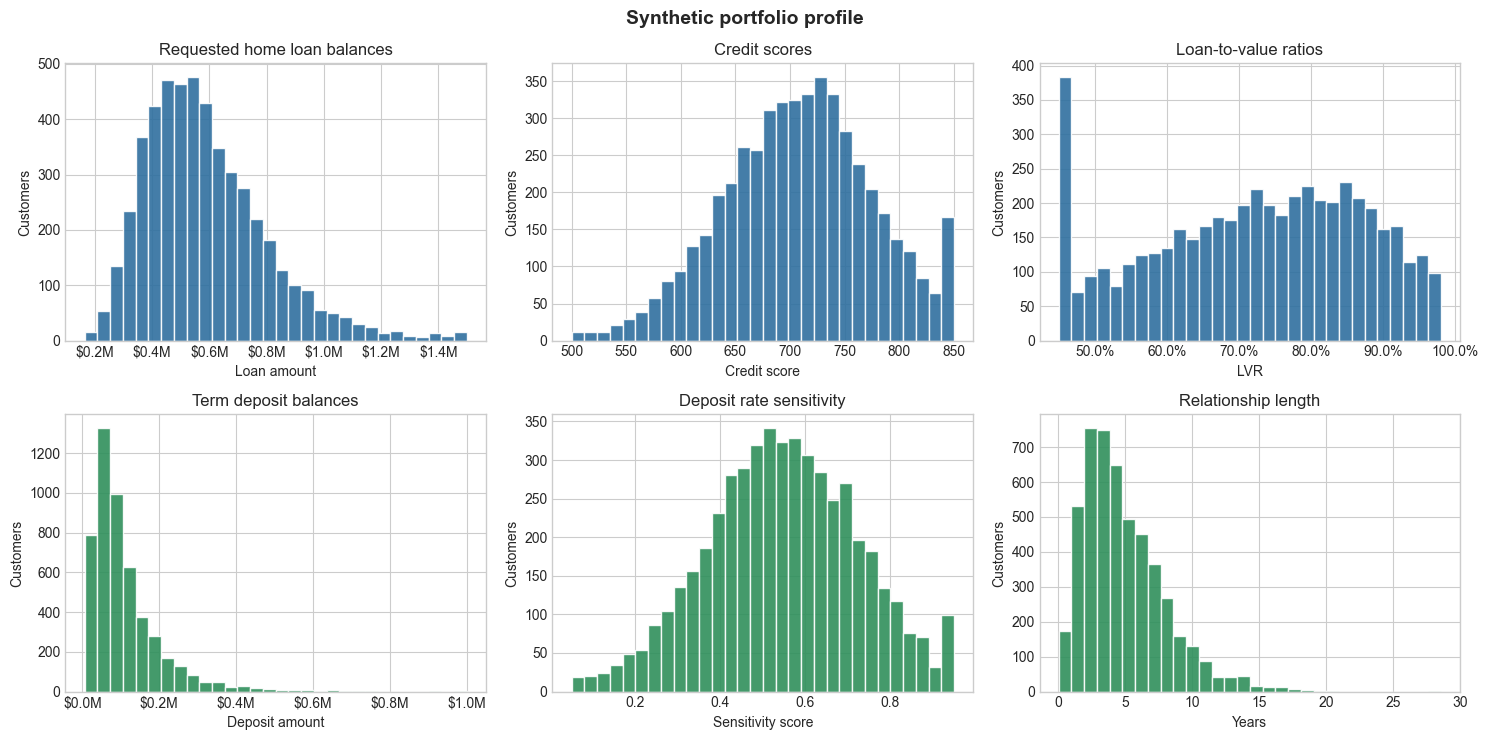

In [15]:
plot_customer_profiles(loan_customers, deposit_customers)


### Customer Relationship Pictures
The histogram charts showed one column at a time. These scatterplots show two ideas at once:

- for home loans, how credit score and loan-to-value relate to synthetic risk,
- for term deposits, how balance size and rate sensitivity relate to customer tenure.

Each dot is one synthetic customer. The colours help you see patterns without reading every row.


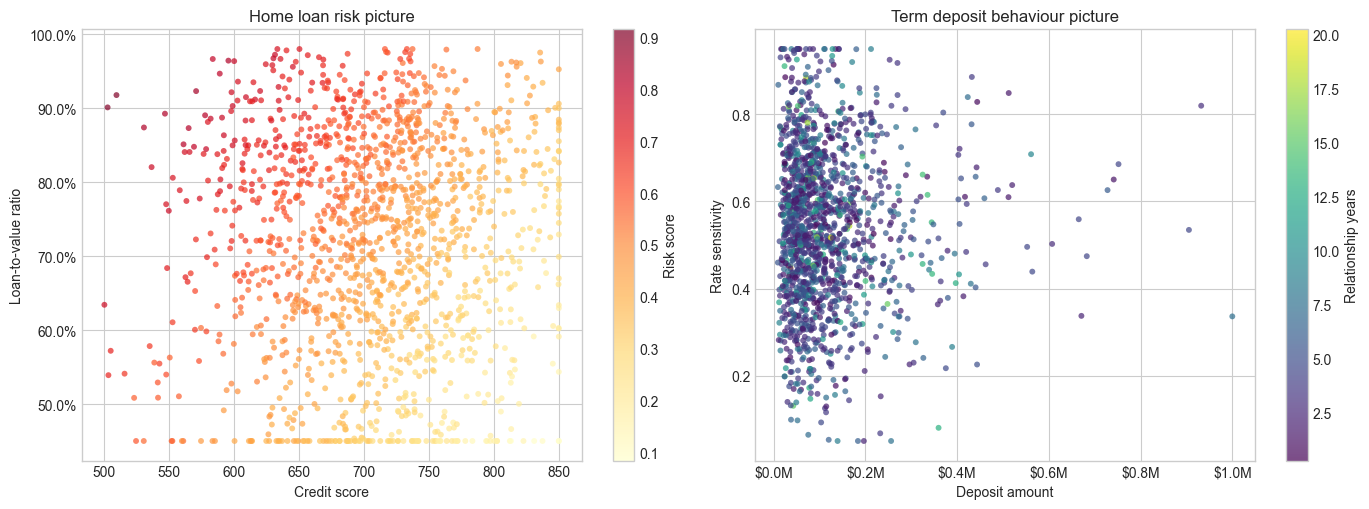

In [16]:
plot_customer_relationships(loan_customers, deposit_customers)


### Data Step 5: Build Candidate Rate Grids
The optimiser does an exhaustive grid search. That means it tests every allowed home-loan-rate and term-deposit-rate combination.

Example:

```text
loan rates     = 5.25%, 5.30%, 5.35%, ...
deposit rates  = 3.60%, 3.65%, 3.70%, ...
```

The more grid points you add, the more combinations the optimiser must evaluate.


In [17]:
loan_grid, deposit_grid = build_configured_rate_grids(config)
rate_grid_table = build_rate_grid_table(
    {"home loan": loan_grid, "term deposit": deposit_grid}
)
rate_grid_table


,grid,rate_decimal,rate_percent
0,home loan,0.0475,4.75%
1,home loan,0.0480,4.80%
2,home loan,0.0485,4.85%
3,home loan,0.0490,4.90%
4,home loan,0.0495,4.95%
5,home loan,0.0500,5.00%
6,home loan,0.0505,5.05%
7,home loan,0.0510,5.10%
8,home loan,0.0515,5.15%
9,home loan,0.0520,5.20%


In [18]:
print(f"Home loan rates tested: {len(loan_grid)}")
print(f"Term deposit rates tested: {len(deposit_grid)}")
print(f"Total pricing combinations tested before adaptive expansion: {len(loan_grid) * len(deposit_grid):,}")

Home loan rates tested: 21
Term deposit rates tested: 17
Total pricing combinations tested before adaptive expansion: 357


### Rate Grid Picture
Think of each rate grid as a ruler. Every dot is a rate the optimiser is allowed to test. The dashed line is the competitor reference rate from the config.

For an absolute beginner: the optimiser cannot choose a rate that is not on one of these rulers unless adaptive boundary expansion adds more points later.


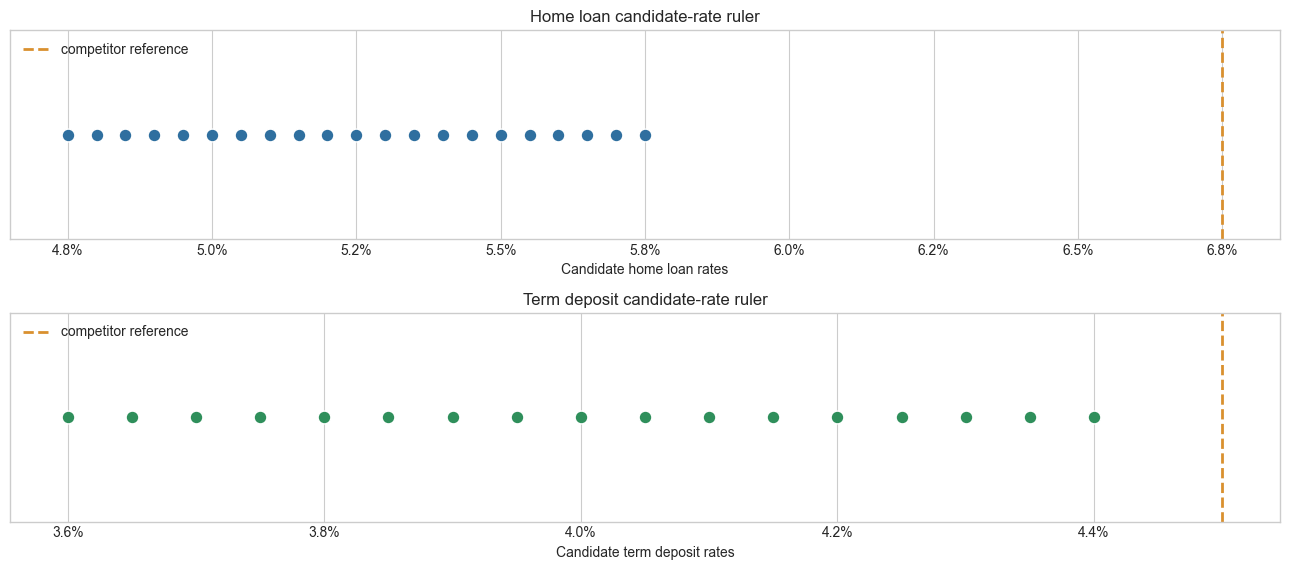

In [19]:
plot_rate_grid_story(
    loan_grid,
    deposit_grid,
    config.market.competitor_loan_rate,
    config.market.competitor_deposit_rate,
)


## Part 2: Pricing Model Steps
This part runs the portfolio-level pricing model and explains its recommendation. The optimiser tests candidate home-loan and term-deposit rates, then ranks each pair by expected risk-adjusted profit after balance-sheet costs and penalties.


### Pricing Model Step 1: Run The Baseline Optimisation
This is the main pricing run. The next cells run the same core workflow as:

```bash
python3 examples/run_baseline.py
```

The output answers:

```text
Which home loan rate and term deposit rate maximise the portfolio objective?
```


In [20]:
diagnostics = run_baseline_diagnostics(config)
result = diagnostics.best_result

print("Baseline optimization complete")
print(f"Grid rows evaluated in final run: {len(diagnostics.grid_results):,}")
print(f"Adaptive expansion rounds: {diagnostics.expansion_rounds}")

Baseline optimization complete
Grid rows evaluated in final run: 2,673
Adaptive expansion rounds: 2


In [21]:
best_decision = build_best_decision_table(result)
format_result_table(best_decision)


,loan_rate,deposit_rate,home_loan_spread_to_market_bps,term_deposit_spread_to_market_bps,objective_value,expected_loan_volume,expected_deposit_volume,funding_shortfall
0,8.00%,5.15%,275 bps,115 bps,"$12,496,386","$604,819,814","$393,936,646",$0


### How To Read The Best Decision Table

Read this table from left to right:

- **loan_rate:** recommended portfolio-level home loan rate.
- **deposit_rate:** recommended portfolio-level term deposit rate.
- **spreads to market:** how far the recommended rates sit above or below the reference market rates.
- **objective_value:** the model's total economic score. Higher is better under the assumptions.
- **expected_loan_volume:** expected accepted synthetic lending balance.
- **expected_deposit_volume:** expected synthetic deposit balance.
- **funding_shortfall:** how much deposit funding is missing after applying the required funding ratio.

A result with a slightly lower objective may still be interesting if it has a lower funding shortfall or fits management constraints better.

### Pricing Model Step 2: Decompose The Winning Objective
This breaks the winning objective into business components so you can see why the selected rate pair won.


The decomposition explains **why** the winning rate pair won.

Positive amounts add value. Negative amounts are costs or penalties. The table includes `excess_deposit_income`, which credits surplus deposits at the configured cash rate when deposit balances exceed required loan funding.


In [22]:
decomposition = diagnostics.winner_decomposition()
objective_decomposition = build_objective_decomposition_table(decomposition)
if "excess_deposit_income" not in set(objective_decomposition["component"]):
    excess_row = pd.DataFrame(
        [{"component": "excess_deposit_income", "amount": decomposition.excess_deposit_income}]
    )
    total_row = objective_decomposition[objective_decomposition["component"] == "total objective"]
    component_rows = objective_decomposition[objective_decomposition["component"] != "total objective"]
    objective_decomposition = pd.concat(
        [component_rows, excess_row, total_row],
        ignore_index=True,
    )
objective_decomposition.assign(amount=objective_decomposition["amount"].map(fmt_money))


,component,amount
0,loan interest income,"$48,385,585"
1,expected credit loss,"$-4,108,330"
2,deposit interest cost,"$-20,287,737"
3,wholesale funding cost,"$-11,493,133"
4,funding shortfall penalty,$-0
5,excess_deposit_income,$0
6,total objective,"$12,496,386"


In [23]:
print("Reconciliation check")
print(f"Reported total objective:     {fmt_money(decomposition.total_objective)}")
print(f"Recalculated total objective: {fmt_money(decomposition.reconciled_total_objective)}")

Reconciliation check
Reported total objective:     $12,496,386
Recalculated total objective: $12,496,386


### Visual Objective Breakdown
The bar chart shows which economic components add value and which components reduce value for the winning rate pair.


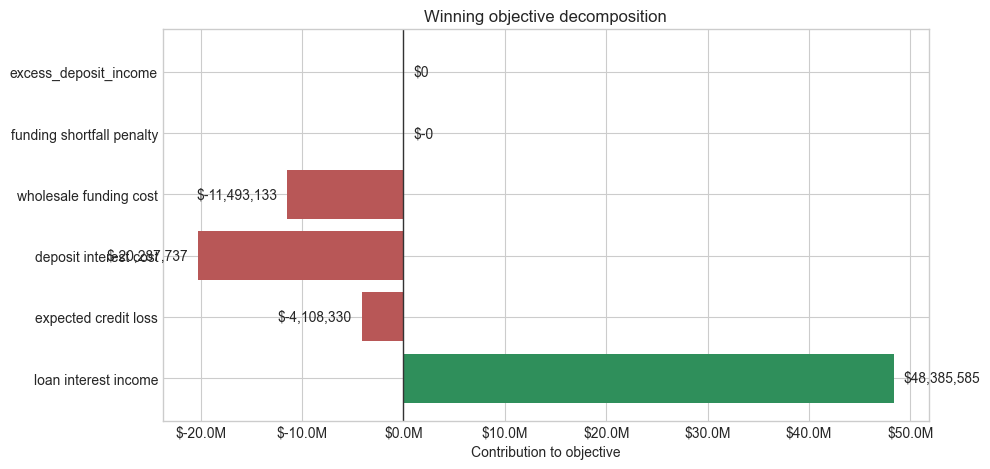

In [24]:
plot_objective_decomposition(objective_decomposition)


### Pricing Model Step 3: Check Boundary Diagnostics
A boundary warning means the best rate is sitting at the edge of the search range. In plain English, the model may be saying: "the best answer might be outside the range you allowed me to search."


In [25]:
import pandas as pd

boundary_flags = {
    "initial_boundary_warning": diagnostics.initial_boundary_diagnostics.warnings != (),
    "final_boundary_warning": diagnostics.boundary_diagnostics.warnings != (),
    "expansion_rounds": diagnostics.expansion_rounds,
    "expansion_capped": diagnostics.expansion_capped,
    "policy_band_breached": diagnostics.policy_band_breached,
}
display(pd.DataFrame([boundary_flags]))
for w in diagnostics.boundary_diagnostics.warnings:
    print("WARNING:", w)


,initial_boundary_warning,final_boundary_warning,expansion_rounds,expansion_capped,policy_band_breached
0,True,False,2,False,True


### Pricing Model Step 4: Compare Top Pricing Candidates
The top candidates help you see whether the winner is clearly better than alternatives. If ranks 1, 2, and 3 are very close, the recommendation may be sensitive to assumptions.


Beginner reading tip:

- If rank 1 is much better than rank 2, the recommendation is more decisive.
- If the top few rows are close, the recommendation depends more heavily on assumptions.
- If a lower-ranked row has much less funding shortfall, it may still be worth business discussion.

In [26]:
top_candidates = diagnostics.top_results(10)
format_result_table(
    top_candidates[
        [
            "loan_rate",
            "deposit_rate",
            "total_objective",
            "expected_loan_volume",
            "expected_deposit_volume",
            "funding_shortfall",
            "home_loan_spread_to_market_bps",
            "term_deposit_spread_to_market_bps",
        ]
    ]
)

,loan_rate,deposit_rate,total_objective,expected_loan_volume,expected_deposit_volume,funding_shortfall,home_loan_spread_to_market_bps,term_deposit_spread_to_market_bps
0,8.00%,5.15%,"$12,496,386","$604,819,814","$393,936,646",$0,275 bps,115 bps
1,8.00%,5.10%,"$12,495,061","$604,819,814","$384,040,808","$9,092,071",275 bps,110 bps
2,8.05%,5.05%,"$12,483,226","$571,538,523","$373,823,791",$0,280 bps,105 bps
3,8.05%,5.00%,"$12,475,355","$571,538,523","$363,307,787","$8,192,253",280 bps,100 bps
4,8.00%,5.05%,"$12,462,307","$604,819,814","$373,823,791","$19,309,088",275 bps,105 bps
5,7.95%,5.15%,"$12,421,925","$639,439,655","$393,936,646","$21,699,129",270 bps,115 bps
6,7.95%,5.20%,"$12,420,855","$639,439,655","$403,492,664","$12,143,112",270 bps,120 bps
7,8.10%,4.95%,"$12,415,531","$539,597,610","$352,518,457",$0,285 bps,95 bps
8,8.00%,5.00%,"$12,412,609","$604,819,814","$363,307,787","$29,825,092",275 bps,100 bps
9,8.05%,4.95%,"$12,408,855","$571,538,523","$352,518,457","$18,981,583",280 bps,95 bps


### Counterfactual Decompositions

Counterfactual decompositions show how the objective components would look for nearby high-ranking alternatives. They help separate a rate choice that wins because of stronger customer volume from one that wins because it avoids funding costs or penalties.


In [27]:
counterfactuals = diagnostics.counterfactual_decompositions(top_n=3)
cf_rows = []
for i, cf in enumerate(counterfactuals):
    row = {"rank": i + 1}
    row.update({k: v for k, v in vars(cf).items()})
    cf_rows.append(row)
cf_df = pd.DataFrame(cf_rows)
display(cf_df)


,rank,loan_interest_income,expected_credit_loss,deposit_interest_cost,wholesale_funding_cost,excess_deposit_income,funding_shortfall_penalty,total_objective,expected_loan_volume,expected_deposit_volume,funding_shortfall
0,1,4.838559e+07,4.108330e+06,2.028774e+07,1.149313e+07,0.0,0.0,1.249639e+07,6.048198e+08,3.939366e+08,0.0
1,2,4.838559e+07,4.108330e+06,2.028774e+07,1.149313e+07,0.0,0.0,1.249639e+07,6.048198e+08,3.939366e+08,0.0
2,3,4.838559e+07,4.108330e+06,2.028774e+07,1.149313e+07,0.0,0.0,1.249639e+07,6.048198e+08,3.939366e+08,0.0


### Cohort Attribution

Cohort attribution breaks the winning expected volumes into coarse synthetic customer segments. It gives a portfolio-level view of which borrower risk bands and depositor balance bands contribute most to the selected pricing outcome.


In [28]:
cohort = diagnostics.cohort_attribution()
cohort_df = pd.DataFrame(cohort).T
cohort_df.index.name = "segment"
display(cohort_df.round(1))


,low,medium,high
segment,,,
loan_volume_by_risk_segment,186657031.8,393616372.5,24546409.5
deposit_volume_by_wealth_segment,28960699.0,169059046.3,195916901.2


### Pricing Model Step 5: Explore The Grid Results
This section summarises the optimisation surface. The tables show the best achievable objective for each single rate, while the charts show how the two-rate decision behaves together.


In [29]:
grid_results = diagnostics.grid_results.copy()

best_by_loan_rate = build_best_by_loan_rate_table(grid_results)
format_result_table(best_by_loan_rate)


,loan_rate,deposit_rate,total_objective,expected_loan_volume,expected_deposit_volume,funding_shortfall
0,4.75%,5.15%,"$-67,001,950","$2,827,379,183","$393,936,646","$1,443,859,822"
1,4.80%,5.15%,"$-65,365,716","$2,819,330,453","$393,936,646","$1,438,628,148"
2,4.85%,5.15%,"$-63,722,485","$2,810,723,938","$393,936,646","$1,433,033,913"
3,4.90%,5.15%,"$-62,072,220","$2,801,526,105","$393,936,646","$1,427,055,322"
4,4.95%,5.15%,"$-60,414,922","$2,791,702,138","$393,936,646","$1,420,669,743"
...,...,...,...,...,...,...
76,8.55%,4.45%,"$9,930,015","$310,165,135","$237,170,534",$0
77,8.60%,4.45%,"$9,602,870","$290,645,630","$237,170,534",$0
78,8.65%,4.45%,"$9,282,745","$272,194,294","$237,170,534",$0
79,8.70%,4.45%,"$8,970,284","$254,771,448","$237,170,534",$0


In [30]:
best_by_deposit_rate = build_best_by_deposit_rate_table(grid_results)
format_result_table(best_by_deposit_rate)


,deposit_rate,loan_rate,total_objective,expected_loan_volume,expected_deposit_volume,funding_shortfall
0,3.60%,8.15%,"$7,402,425","$508,992,979","$83,451,729","$247,393,707"
1,3.65%,8.15%,"$7,583,450","$508,992,979","$89,639,252","$241,206,185"
2,3.70%,8.15%,"$7,771,213","$508,992,979","$96,190,864","$234,654,572"
3,3.75%,8.15%,"$7,965,430","$508,992,979","$103,114,068","$227,731,369"
4,3.80%,8.15%,"$8,165,736","$508,992,979","$110,414,442","$220,430,994"
5,3.85%,8.15%,"$8,371,680","$508,992,979","$118,095,368","$212,750,068"
6,3.90%,8.15%,"$8,582,722","$508,992,979","$126,157,748","$204,687,688"
7,3.95%,8.15%,"$8,798,229","$508,992,979","$134,599,741","$196,245,695"
8,4.00%,8.15%,"$9,017,474","$508,992,979","$143,416,521","$187,428,915"
9,4.05%,8.15%,"$9,239,639","$508,992,979","$152,600,064","$178,245,372"


### Grid Search Pictures
These charts show the optimizer surface: where the objective is highest, how each rate behaves on its own, and how close the top candidates are.


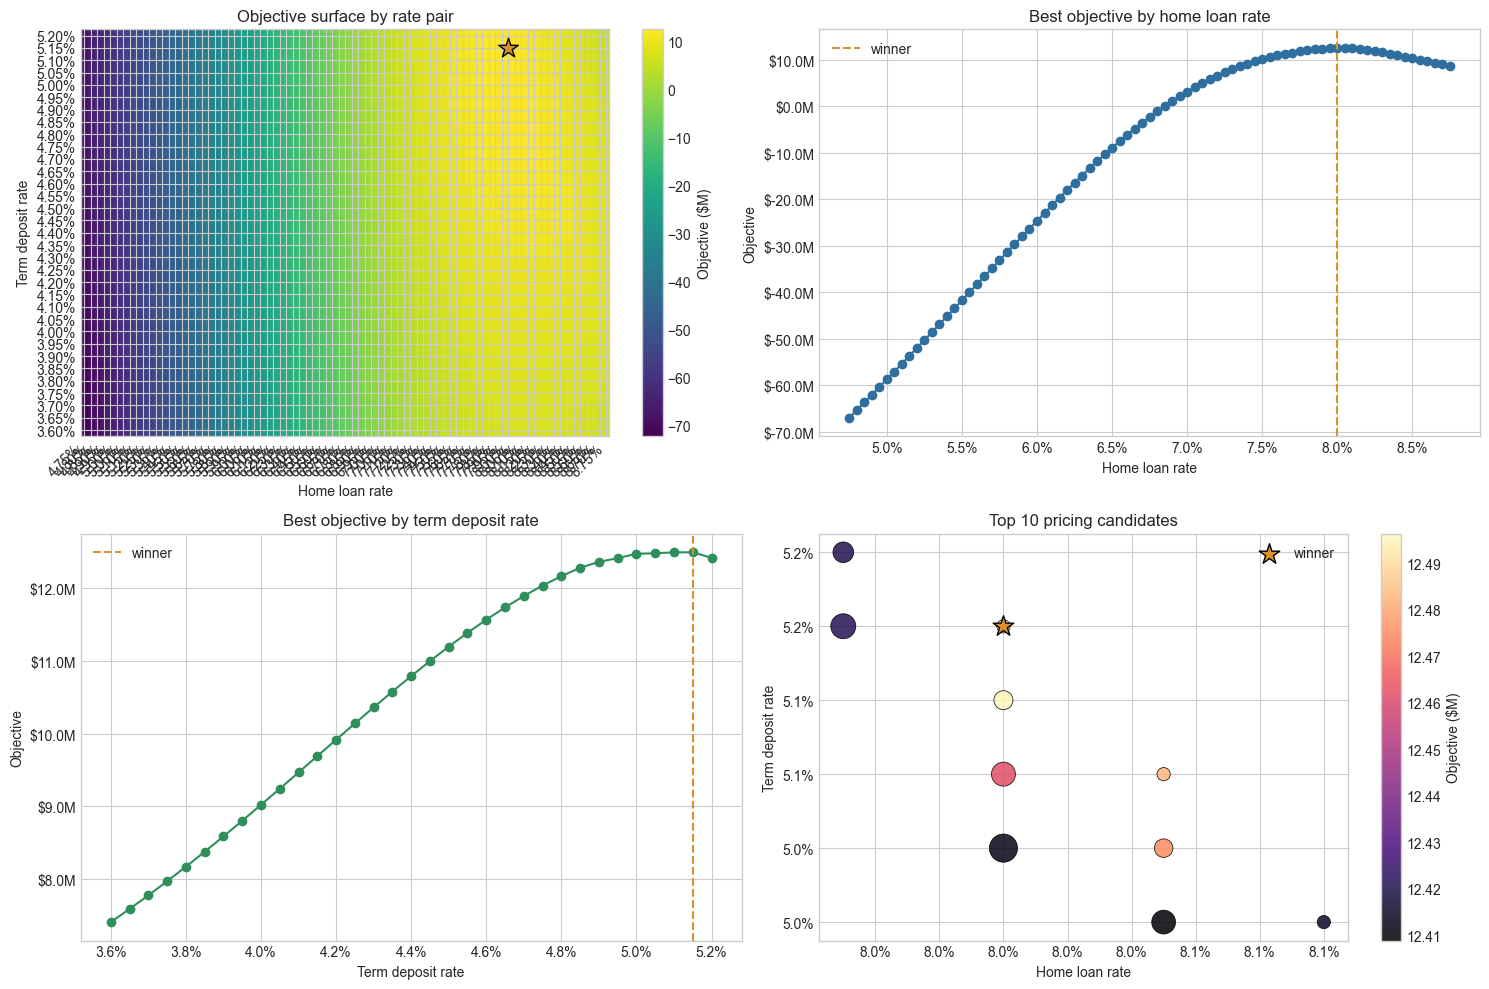

In [31]:
plot_grid_search_results(
    grid_results,
    best_by_loan_rate,
    best_by_deposit_rate,
    top_candidates,
    result,
)


### Beginner Trade-Off Pictures
These charts slow the optimiser down into four simpler ideas:

- higher home-loan rates usually mean fewer accepted loans,
- higher deposit rates usually mean more deposit funding,
- the model ranks candidate rate pairs by objective,
- a high-ranked candidate can still have a funding shortfall.

This is often the easiest picture to use when explaining why the winning rate pair is a trade-off, not just "highest loan rate" or "lowest deposit rate."


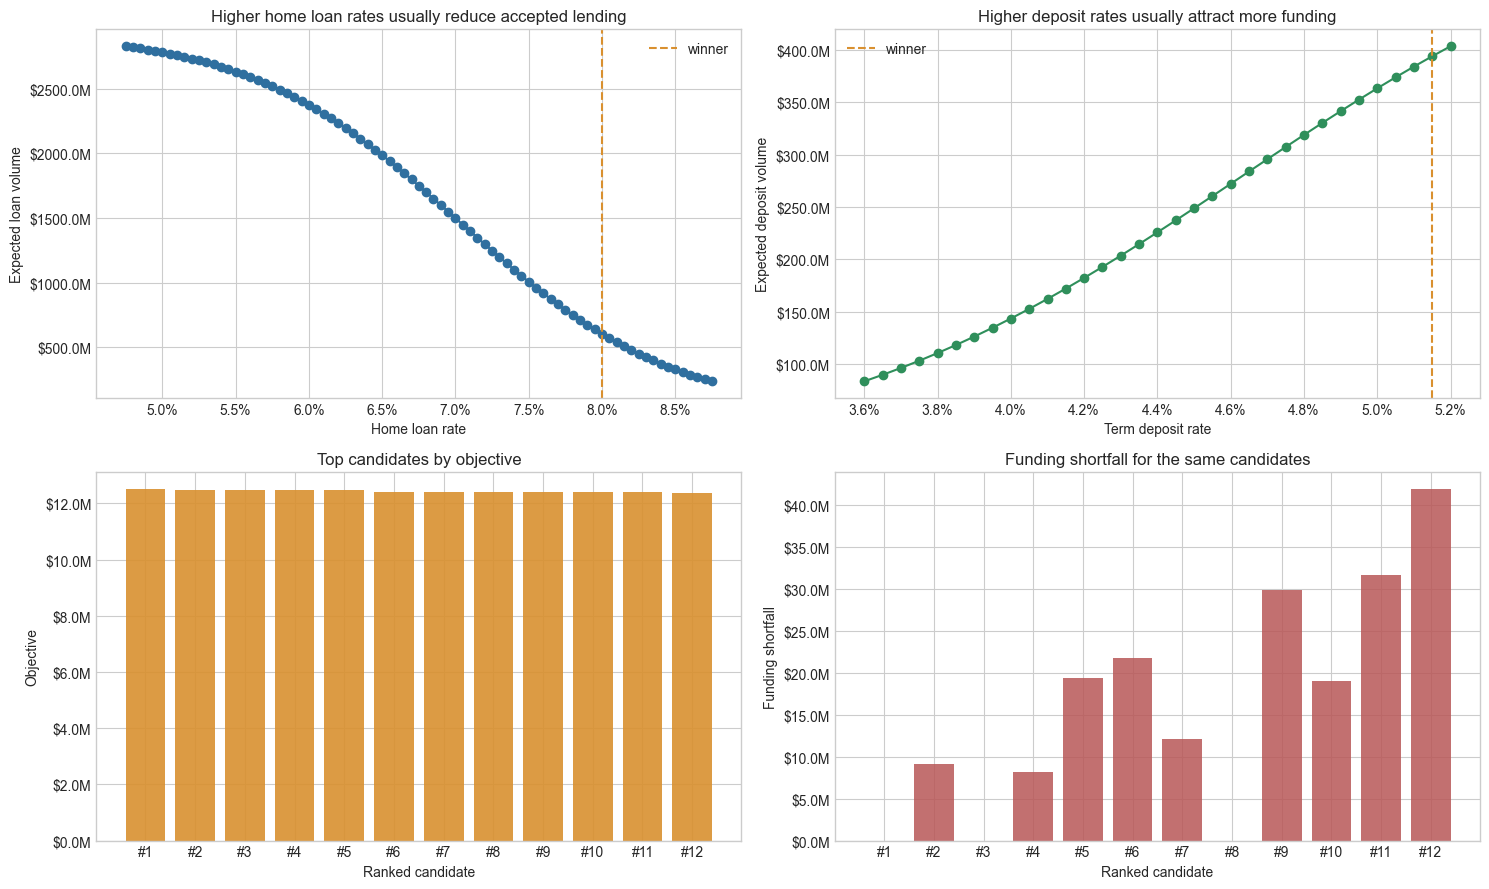

In [32]:
plot_volume_and_funding_story(grid_results, result)


### Pricing Model Step 6: Run Sensitivity Analysis
Sensitivity analysis asks: **what changes if our assumptions are wrong?**

The notebook reruns the optimiser under alternative assumptions such as:
- weaker or stronger customer rate response
- different wholesale funding cost
- different funding shortfall penalty
- different competitor rates


In [33]:
sensitivity = run_sensitivity_analysis(config)
sensitivity["parameter_name"] = sensitivity["scenario_name"]
cols = ["parameter_name", "parameter_family", "delta_loan_rate_bps", "delta_deposit_rate_bps", "delta_objective_pct"]
display(sensitivity[cols])


,parameter_name,parameter_family,delta_loan_rate_bps,delta_deposit_rate_bps,delta_objective_pct
0,baseline,funding,0.0,0.0,0.000000
1,loan_elasticity_weaker,elasticity,25.0,-5.0,0.119854
2,loan_elasticity_stronger,elasticity,-15.0,-10.0,-0.086788
3,deposit_elasticity_weaker,elasticity,5.0,-5.0,-0.024849
4,deposit_elasticity_stronger,elasticity,0.0,-10.0,0.024684
5,loan_competitor_gap_elasticity_weaker,elasticity,15.0,0.0,0.074401
6,loan_competitor_gap_elasticity_stronger,elasticity,-10.0,-5.0,-0.058417
7,deposit_competitor_gap_elasticity_weaker,elasticity,5.0,-5.0,-0.018462
8,deposit_competitor_gap_elasticity_stronger,elasticity,0.0,-10.0,0.019024
9,loan_risk_score_coef_weaker,elasticity,10.0,-5.0,0.038488


### Monte Carlo Sensitivity: Cohort Uncertainty

The one-at-a-time sensitivity table above uses one synthetic customer draw. Monte Carlo sensitivity repeats each case across `n_seeds` synthetic cohorts, then reports mean outcomes and standard errors to show sampling uncertainty.


In [34]:
sensitivity_mc = run_sensitivity_analysis(config, n_seeds=5)
sensitivity_mc["parameter_name"] = sensitivity_mc["scenario_name"]
mc_cols = [
    c
    for c in sensitivity_mc.columns
    if "mean" in c or "std_error" in c or c in ["parameter_name", "parameter_family"]
]
display(sensitivity_mc[mc_cols])


,parameter_family,best_loan_rate_mean,best_loan_rate_std_error,best_deposit_rate_mean,best_deposit_rate_std_error,objective_value_mean,objective_value_std_error,expected_loan_volume_mean,expected_loan_volume_std_error,expected_deposit_volume_mean,expected_deposit_volume_std_error,funding_shortfall_mean,funding_shortfall_std_error,parameter_name
0,funding,0.0801,0.000100,0.0510,0.000158,1.256835e+07,54575.643144,5.999952e+08,6.783927e+06,3.850915e+08,4.704464e+06,5.066166e+06,1.433016e+06,baseline
1,elasticity,0.0825,0.000000,0.0511,0.000100,1.406835e+07,59253.245271,6.052406e+08,1.572844e+06,3.870470e+08,8.829194e+05,6.359400e+06,8.549425e+05,loan_elasticity_weaker
2,elasticity,0.0785,0.000000,0.0505,0.000158,1.146983e+07,54313.017757,5.791095e+08,1.530167e+06,3.747665e+08,2.315586e+06,1.748512e+06,1.375417e+06,loan_elasticity_stronger
3,elasticity,0.0806,0.000100,0.0509,0.000100,1.225631e+07,54255.776089,5.669918e+08,6.517038e+06,3.660025e+08,3.863715e+06,2.543896e+06,8.634714e+05,deposit_elasticity_weaker
4,elasticity,0.0800,0.000000,0.0506,0.000100,1.287546e+07,55339.570141,6.066535e+08,1.575106e+06,3.926274e+08,8.830317e+05,1.971612e+06,6.072121e+05,deposit_elasticity_stronger
5,elasticity,0.0817,0.000122,0.0510,0.000158,1.348968e+07,56076.785165,5.958658e+08,6.755312e+06,3.850309e+08,3.259928e+06,2.596967e+06,1.682230e+06,loan_competitor_gap_elasticity_weaker
6,elasticity,0.0790,0.000000,0.0507,0.000122,1.183500e+07,53309.885124,5.901293e+08,1.548358e+06,3.789307e+08,1.334984e+06,4.983922e+06,1.413720e+06,loan_competitor_gap_elasticity_stronger
7,elasticity,0.0805,0.000000,0.0510,0.000158,1.232654e+07,55738.724166,5.733833e+08,1.520601e+06,3.714138e+08,2.079937e+06,1.418847e+06,1.099856e+06,deposit_competitor_gap_elasticity_weaker
8,elasticity,0.0800,0.000000,0.0506,0.000100,1.280928e+07,54778.633097,6.066535e+08,1.575106e+06,3.893799e+08,8.776129e+05,4.944897e+06,8.414917e+05,deposit_competitor_gap_elasticity_stronger
9,elasticity,0.0810,0.000000,0.0510,0.000158,1.303835e+07,57666.858933,5.964695e+08,1.461116e+06,3.849864e+08,2.236456e+06,2.718808e+06,1.326264e+06,loan_risk_score_coef_weaker


In [35]:
from balance_pricing_engine.reporting import build_sensitivity_tornado_table

tornado = build_sensitivity_tornado_table(sensitivity_mc)
display(tornado)


,scenario_name,parameter_family,delta_loan_rate_bps,delta_deposit_rate_bps,delta_objective_pct
0,loan_elasticity_weaker,elasticity,+25 bps,-5 bps,+11.99%
1,competitor_loan_rate_higher,competitor,+20 bps,+0 bps,+10.59%
2,wholesale_funding_rate_lower,wholesale,-20 bps,-15 bps,+10.57%
3,competitor_loan_rate_lower,competitor,-15 bps,-15 bps,-9.77%
4,loan_elasticity_stronger__funding_penalty_higher,elasticity,-15 bps,-10 bps,-8.78%
5,loan_elasticity_stronger,elasticity,-15 bps,-10 bps,-8.68%
6,wholesale_funding_rate_higher,wholesale,+5 bps,-10 bps,-8.02%
7,loan_competitor_gap_elasticity_weaker,elasticity,+15 bps,+0 bps,+7.44%
8,competitor_deposit_rate_lower,competitor,+0 bps,-25 bps,+6.91%
9,competitor_deposit_rate_lower__funding_penalty...,competitor,+0 bps,-25 bps,+6.55%


In [36]:
sensitivity_summary = build_sensitivity_change_table(sensitivity)
formatted_sensitivity_summary = build_sensitivity_summary_table(sensitivity)
formatted_sensitivity_summary


,scenario_name,loan_rate_change_vs_baseline,deposit_rate_change_vs_baseline,objective_change_vs_baseline,funding_shortfall,boundary_warning_flag
0,baseline,+0 bps,+0 bps,$0,$0,False
1,loan_elasticity_weaker,+25 bps,-5 bps,"$1,497,743","$8,173,310",False
2,loan_elasticity_stronger,-15 bps,-10 bps,"$-1,084,539","$1,399,085",False
3,deposit_elasticity_weaker,+5 bps,-5 bps,"$-310,519","$4,758,799",False
4,deposit_elasticity_stronger,+0 bps,-10 bps,"$308,461","$3,739,133",False
5,loan_competitor_gap_elasticity_weaker,+15 bps,+0 bps,"$929,747",$0,False
6,loan_competitor_gap_elasticity_stronger,-10 bps,-5 bps,"$-730,000",$0,False
7,deposit_competitor_gap_elasticity_weaker,+5 bps,-5 bps,"$-230,714","$1,046,938",False
8,deposit_competitor_gap_elasticity_stronger,+0 bps,-10 bps,"$237,727","$6,954,301",False
9,loan_risk_score_coef_weaker,+10 bps,-5 bps,"$480,959","$2,680,819",False


### Sensitivity Pictures
These charts make it easier to see which assumptions move the recommendation and which scenarios mainly move profit.


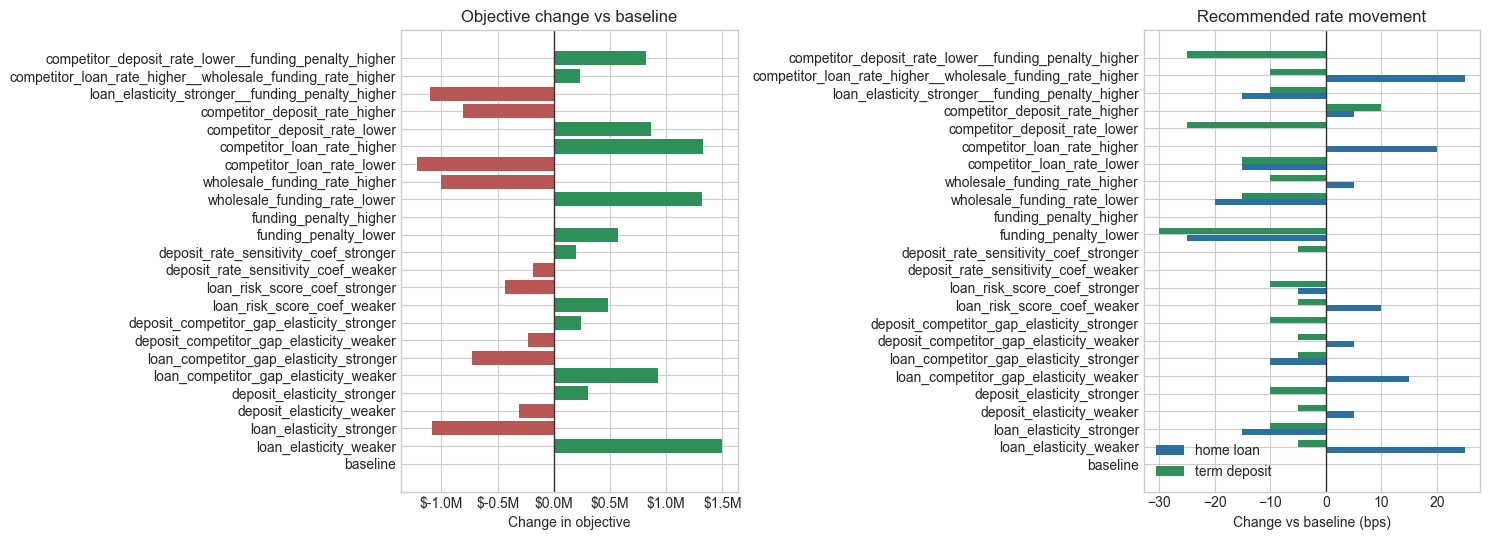

In [37]:
plot_sensitivity_summary(sensitivity_summary)


### Pricing Model Step 7: Try Your Own Scenario
This is the first section where beginners can safely experiment. The example below changes the config **in memory only**. It does not edit `configs/base.yaml`.


In [38]:
scenario_diagnostics = run_higher_funding_penalty_scenario(config, multiplier=1.5)
scenario_result = scenario_diagnostics.best_result

comparison = build_scenario_comparison_table(result, scenario_result)
format_result_table(comparison)


,scenario,loan_rate,deposit_rate,objective_value,expected_loan_volume,expected_deposit_volume,funding_shortfall
0,baseline,8.00%,5.15%,"$12,496,386","$604,819,814","$393,936,646",$0
1,higher funding penalty,8.00%,5.15%,"$12,496,386","$604,819,814","$393,936,646",$0


## Part 3: Response Modelling Steps
This part switches from the pricing optimiser to learned response models. It creates synthetic observed outcomes, trains simple classifiers, and checks whether the learned models behave sensibly as offered rates move.


### Response Modelling Step 1: Train Synthetic Response Models
This section is optional for a first beginner run. The optimiser itself uses known synthetic response functions. This section trains simple models on synthetic observed outcomes to demonstrate a modelling workflow:

```text
synthetic customer data + offered rate -> observed accept / not accept
```

The goal is not to create a production model. The goal is to show the checks a response model should pass before you trust it.


In [39]:
response_workflow = run_response_model_workflow(config)
loan_dataset = response_workflow.loan_dataset
deposit_dataset = response_workflow.deposit_dataset
loan_model_report = response_workflow.loan_model_report
deposit_model_report = response_workflow.deposit_model_report

print(f"Loan response rows: {len(loan_dataset):,}")
print(f"Deposit response rows: {len(deposit_dataset):,}")


Loan response rows: 15,000
Deposit response rows: 15,000


In [40]:
loan_dataset.head()

,customer_id,product,offered_rate,competitor_rate,rate_gap_to_competitor,loan_amount,credit_score,lvr,income,risk_score,expected_loss_rate,risk_segment,ground_truth_probability,accepted
0,L003603,home_loan,0.0480,0.0675,-0.0195,423586.648700,812.071957,0.577393,97303.900448,0.216282,0.003610,0,0.987590,1
1,L000685,home_loan,0.0540,0.0675,-0.0135,803048.045173,676.462778,0.754890,214391.075105,0.536473,0.009027,1,0.897902,1
2,L003865,home_loan,0.0575,0.0675,-0.0100,761370.017559,633.521201,0.908947,118930.898583,0.743259,0.013381,2,0.703818,1
3,L004780,home_loan,0.0485,0.0675,-0.0190,378848.704301,685.613095,0.475966,95487.730849,0.341595,0.005501,1,0.981336,1
4,L001775,home_loan,0.0530,0.0675,-0.0145,496793.676127,730.784111,0.450000,56363.165628,0.287339,0.004641,0,0.972760,1


In [41]:
deposit_dataset.head()

,customer_id,product,offered_rate,competitor_rate,rate_gap_to_competitor,deposit_amount,relationship_years,digital_engagement,rate_sensitivity,wealth_segment,ground_truth_probability,opened
0,D001086,term_deposit,0.0410,0.045,-0.0040,40166.303808,1.872593,0.186303,0.650411,0,0.288617,0
1,D001630,term_deposit,0.0435,0.045,-0.0015,177587.043417,1.399996,0.659586,0.665962,2,0.358624,1
2,D003368,term_deposit,0.0380,0.045,-0.0070,18192.646765,2.509182,0.017999,0.711109,0,0.211390,0
3,D002613,term_deposit,0.0435,0.045,-0.0015,62666.200262,4.849189,0.521211,0.898370,1,0.431373,0
4,D001047,term_deposit,0.0400,0.045,-0.0050,92638.701638,4.923041,0.249150,0.482817,1,0.256695,0


### Observed Response Pictures
Before looking at model metrics, look at the synthetic observed behaviour. The solid line is the sampled outcome rate in the training data. The dashed line is the known synthetic ground-truth probability.

Beginner reading tip: loan acceptance should generally fall as the offered loan rate rises; deposit uptake should generally rise as the offered deposit rate rises.


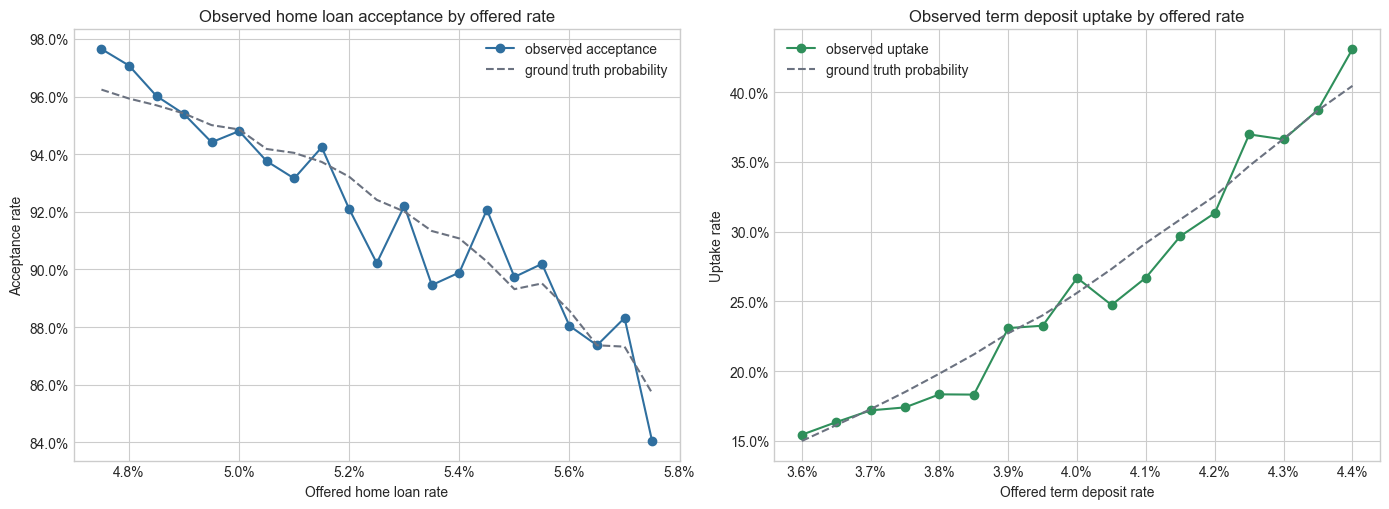

In [42]:
plot_response_dataset_overview(loan_dataset, deposit_dataset)


In [43]:
# Response model reports were trained by run_response_model_workflow above.


In [44]:
from balance_pricing_engine.modelling.evaluation import evaluate_probabilities, evaluate_model

loan_model = loan_model_report["model"]
deposit_model = deposit_model_report["model"]
loan_metrics = evaluate_model(loan_model, loan_dataset, LOAN_FEATURE_COLUMNS, LOAN_TARGET_COLUMN)
deposit_metrics = evaluate_model(deposit_model, deposit_dataset, DEPOSIT_FEATURE_COLUMNS, DEPOSIT_TARGET_COLUMN)
model_metrics = pd.DataFrame(
    [
        {"model": loan_model_report["title"], **loan_metrics},
        {"model": deposit_model_report["title"], **deposit_metrics},
    ]
)
display(model_metrics)


,model,auc,log_loss,brier_score
0,Home loan acceptance model,0.709289,0.260093,0.070996
1,Term deposit uptake model,0.630486,0.553503,0.184845


### Model Metric Interpretation

- **AUC**: ranking quality. Higher is better; `0.5` is no better than random ranking.
- **Log loss**: probability accuracy with a strong penalty for confident wrong predictions. Lower is better.
- **Brier score**: squared probability error. Lower is better.

These are diagnostics for the synthetic response-model layer, not production model approval metrics.

In [45]:
print(loan_model_report["title"])
display(loan_model_report["calibration"])
print(deposit_model_report["title"])
display(deposit_model_report["calibration"])

Home loan acceptance model


,bin,mean_predicted_probability,observed_rate,count
0,2,0.585553,1.000000,2
1,3,0.753200,0.769912,226
2,4,0.927827,0.926732,4272


Term deposit uptake model


,bin,mean_predicted_probability,observed_rate,count
0,0,0.162443,0.150675,1407
1,1,0.288561,0.299382,2749
2,2,0.433648,0.401163,344


In [46]:
loan_response_check = loan_model_report["response_check"]
deposit_response_check = deposit_model_report["response_check"]

print(f"Loan response direction sane: {loan_response_check.is_directionally_sane} | violations: {loan_response_check.violations}")
display(loan_response_check.rate_response.assign(offered_rate=loan_response_check.rate_response["offered_rate"].map(fmt_rate)))

print(f"Deposit response direction sane: {deposit_response_check.is_directionally_sane} | violations: {deposit_response_check.violations}")
display(deposit_response_check.rate_response.assign(offered_rate=deposit_response_check.rate_response["offered_rate"].map(fmt_rate)))

Loan response direction sane: True | violations: 0


,offered_rate,mean_predicted_probability
0,4.75%,0.965100
1,4.80%,0.962321
2,4.85%,0.959332
3,4.90%,0.956122
4,4.95%,0.952675
5,5.00%,0.948976
6,5.05%,0.945011
7,5.10%,0.940763
8,5.15%,0.936217
9,5.20%,0.931355


Deposit response direction sane: True | violations: 0


,offered_rate,mean_predicted_probability
0,3.60%,0.142989
1,3.65%,0.154204
2,3.70%,0.166126
3,3.75%,0.178771
4,3.80%,0.192153
5,3.85%,0.206282
6,3.90%,0.221160
7,3.95%,0.236787
8,4.00%,0.253155
9,4.05%,0.270250


### Response Model Pictures
The calibration plots compare predicted probabilities with observed synthetic outcomes. The response curves show whether predicted customer behaviour moves in the expected direction as rates change.


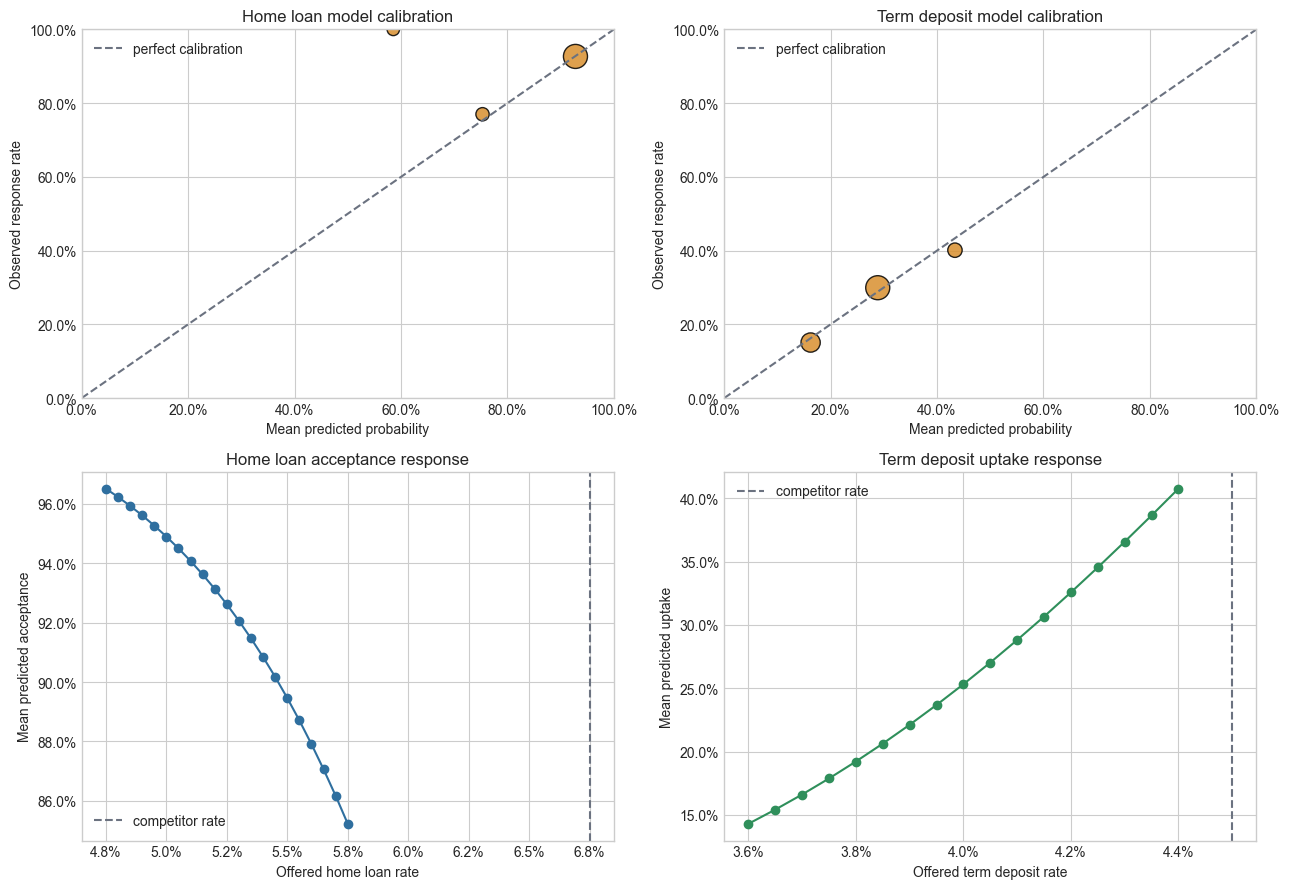

In [47]:
plot_response_model_report(
    loan_model_report,
    deposit_model_report,
    loan_response_check,
    deposit_response_check,
    config.market.competitor_loan_rate,
    config.market.competitor_deposit_rate,
)


## Part 4: Governed Modelling Steps
This part demonstrates the recent governed modelling additions. It keeps the deterministic elasticity response model as the transparent baseline champion, trains a logistic challenger, records local lineage, and shows how scoring falls back safely when no approved artifact is available.

This is still **decision-support only**. The workflow recommends candidates for human review; it does not autonomously promote models or set prices.


### Governed Modelling Step 1: Train Champion/Challenger Candidates
The training agent compares two candidates for each product:

- **Elasticity baseline:** transparent synthetic ground-truth response logic.
- **Logistic challenger:** learned response model trained from synthetic observed outcomes.

The output includes validation metrics, calibration error, a governance score, and a recommendation. Artifacts and registry records are written under `data/outputs/agentic_notebook/`, which is ignored by git.


In [48]:
from balance_pricing_engine.modelling.agentic import (
    ElasticityBaselineModel,
    LogisticResponseModel,
    ModelRegistry,
    ModelTrainingAgent,
    TrainingConfig,
)

agentic_artifacts_dir = PROJECT_ROOT / "data" / "outputs" / "agentic_notebook"
agentic_results = {}
agentic_runs = [
    (
        "Home loan",
        "loan",
        loan_dataset,
        LOAN_FEATURE_COLUMNS,
        LOAN_TARGET_COLUMN,
        {"elasticity_baseline": ElasticityBaselineModel(), "logistic": LogisticResponseModel()},
    ),
    (
        "Term deposit",
        "deposit",
        deposit_dataset,
        DEPOSIT_FEATURE_COLUMNS,
        DEPOSIT_TARGET_COLUMN,
        {"elasticity_baseline": ElasticityBaselineModel(), "logistic": LogisticResponseModel()},
    ),
]

agentic_candidate_rows = []

for product_label, product, dataset, features, target, candidates in agentic_runs:
    artifact_dir = agentic_artifacts_dir / product
    agent = ModelTrainingAgent(
        config=TrainingConfig(
            feature_columns=features,
            target_column=target,
            random_seed=config.random_seed,
        ),
        artifacts_dir=artifact_dir,
    )
    registry = ModelRegistry(artifact_dir / "registry.json")
    result = agent.train(
        dataset=dataset,
        candidates=candidates,
        registry=registry,
        feature_columns=features,
        target_column=target,
        run_name=f"{product}_walkthrough",
    )
    agentic_results[product] = result
    print(f"{product}: recommended={result.recommended_model_name}, records={len(result.records)}")

    for candidate in result.report["candidates"]:
        agentic_candidate_rows.append(
            {
                "product": product_label,
                "candidate": candidate["model_name"],
                "passed_validation": candidate["passed_validation"],
                "governance_score": candidate["governance_score"],
                "auc": candidate["metrics"]["auc"],
                "log_loss": candidate["metrics"]["log_loss"],
                "brier_score": candidate["metrics"]["brier_score"],
                "calibration_error": candidate["calibration_error"],
                "artifact_path": candidate["artifact_path"],
            }
        )

agentic_candidate_summary = pd.DataFrame(agentic_candidate_rows)
display(agentic_candidate_summary)


loan: recommended=elasticity_baseline, records=2
deposit: recommended=elasticity_baseline, records=2


,product,candidate,passed_validation,governance_score,auc,log_loss,brier_score,calibration_error,artifact_path
0,Home loan,ElasticityBaselineModel,False,0.205228,0.722219,0.258327,0.070841,0.158954,/Users/kevinchang/Documents/ai-bank-pricing-en...
1,Home loan,LogisticResponseModel,False,0.084041,0.719380,0.258612,0.070855,0.163192,/Users/kevinchang/Documents/ai-bank-pricing-en...
2,Term deposit,ElasticityBaselineModel,True,0.955758,0.636933,0.551584,0.184267,0.008848,/Users/kevinchang/Documents/ai-bank-pricing-en...
3,Term deposit,LogisticResponseModel,True,0.886774,0.636367,0.551676,0.184306,0.002645,/Users/kevinchang/Documents/ai-bank-pricing-en...


### Governed Modelling Step 2: Review Recommendations
A challenger only becomes a recommendation if it passes calibration controls and improves log loss by enough to clear the configured threshold.

Even then, the report marks the workflow as requiring human approval. That is intentional model-governance behaviour, not a notebook warning.


In [49]:
for product, result in agentic_results.items():
    print()
    print(f"--- {product.upper()} ---")
    print(f"Recommended model: {result.recommended_model_name}")
    print(f"Report path: {result.report_path}")
    for rec in result.records:
        print(f"  {rec.model_name}: log_loss={rec.metrics['log_loss']:.4f}")

agentic_recommendations = pd.DataFrame(
    [
        {
            "product": product,
            "recommended_model": result.recommended_model_name,
            "recommend_as": result.report["recommendation"]["recommend_as"],
            "log_loss_improvement_vs_baseline": result.report["recommendation"][
                "log_loss_improvement_vs_baseline"
            ],
            "human_approval_required": result.report["required_human_approval"],
            "report_path": result.report_path,
        }
        for product, result in agentic_results.items()
    ]
)
display(agentic_recommendations)



--- LOAN ---
Recommended model: elasticity_baseline
Report path: /Users/kevinchang/Documents/ai-bank-pricing-engine/data/outputs/agentic_notebook/loan/reports/training_report_20260505144112771389.json
  ElasticityBaselineModel: log_loss=0.2583
  LogisticResponseModel: log_loss=0.2586

--- DEPOSIT ---
Recommended model: elasticity_baseline
Report path: /Users/kevinchang/Documents/ai-bank-pricing-engine/data/outputs/agentic_notebook/deposit/reports/training_report_20260505144112818068.json
  ElasticityBaselineModel: log_loss=0.5516
  LogisticResponseModel: log_loss=0.5517


,product,recommended_model,recommend_as,log_loss_improvement_vs_baseline,human_approval_required,report_path
0,loan,elasticity_baseline,baseline_champion,0.0,True,/Users/kevinchang/Documents/ai-bank-pricing-en...
1,deposit,elasticity_baseline,baseline_champion,0.0,True,/Users/kevinchang/Documents/ai-bank-pricing-en...


### Governed Modelling Step 3: Inspect The Local Model Registry
The registry is a lightweight JSON audit trail. It records candidate metadata, governance status, champion/challenger labels, artifact paths, config hashes, and the training report path.

Rerunning this cell after retraining can show multiple records because the registry is append-only.


In [50]:
registry_rows = []
for product_label, product, *_ in agentic_runs:
    registry_path = agentic_artifacts_dir / product / "registry.json"
    registry_payload = ModelRegistry(registry_path).load()
    for record in registry_payload.get("models", []):
        registry_rows.append(
            {
                "product": product_label,
                "model_name": record.get("model_name"),
                "champion_status": record.get("champion_status"),
                "governance_status": record.get("governance_status"),
                "artifact_path": record.get("artifact_path"),
                "report_path": record.get("report_path"),
            }
        )

agentic_registry = pd.DataFrame(registry_rows)
agentic_registry.tail(8)


,product,model_name,champion_status,governance_status,artifact_path,report_path
4,Home loan,ElasticityBaselineModel,baseline_champion,pending_human_approval,/Users/kevinchang/Documents/ai-bank-pricing-en...,/Users/kevinchang/Documents/ai-bank-pricing-en...
5,Home loan,LogisticResponseModel,challenger_candidate,pending_human_approval,/Users/kevinchang/Documents/ai-bank-pricing-en...,/Users/kevinchang/Documents/ai-bank-pricing-en...
6,Term deposit,ElasticityBaselineModel,baseline_champion,pending_human_approval,/Users/kevinchang/Documents/ai-bank-pricing-en...,/Users/kevinchang/Documents/ai-bank-pricing-en...
7,Term deposit,LogisticResponseModel,challenger_candidate,pending_human_approval,/Users/kevinchang/Documents/ai-bank-pricing-en...,/Users/kevinchang/Documents/ai-bank-pricing-en...
8,Term deposit,ElasticityBaselineModel,baseline_champion,pending_human_approval,/Users/kevinchang/Documents/ai-bank-pricing-en...,/Users/kevinchang/Documents/ai-bank-pricing-en...
9,Term deposit,LogisticResponseModel,challenger_candidate,pending_human_approval,/Users/kevinchang/Documents/ai-bank-pricing-en...,/Users/kevinchang/Documents/ai-bank-pricing-en...
10,Term deposit,ElasticityBaselineModel,baseline_champion,pending_human_approval,/Users/kevinchang/Documents/ai-bank-pricing-en...,/Users/kevinchang/Documents/ai-bank-pricing-en...
11,Term deposit,LogisticResponseModel,challenger_candidate,pending_human_approval,/Users/kevinchang/Documents/ai-bank-pricing-en...,/Users/kevinchang/Documents/ai-bank-pricing-en...


### Governed Modelling Step 4: Score A Sample With Fallback Controls
The scoring agent validates the feature schema, loads a model artifact when one exists, and otherwise falls back to the transparent elasticity model.

This cell scores a small home-loan sample. If the recommended model is the baseline champion, there is no learned artifact to load, so fallback use is expected.


In [51]:
loan_result = agentic_results["loan"]
loan_recommended_record = next(
    rec
    for rec in loan_result.records
    if rec.model_name == loan_result.report["recommendation"]["recommended_model"]
    or rec.model_name == loan_result.recommended_model_name
)

loan_scoring_agent = ModelScoringAgent(feature_columns=LOAN_FEATURE_COLUMNS)
loan_score = loan_scoring_agent.score(
    loan_dataset.head(50),
    model_artifact_path=loan_recommended_record.artifact_path,
    run_name="loan_response_score_sample",
)

pd.DataFrame(
    [
        {
            "model_used": loan_score["model_used"],
            "used_fallback": loan_score["used_fallback"],
            "rows_scored": loan_score["rows"],
            "mean_probability": loan_score["mean_probability"],
            "min_probability": loan_score["min_probability"],
            "max_probability": loan_score["max_probability"],
            "expected_acceptances": loan_score["expected_volume"],
            "explanation": loan_score["explanation"],
        }
    ]
)


,model_used,used_fallback,rows_scored,mean_probability,min_probability,max_probability,expected_acceptances,explanation
0,LoadedLogisticModel,False,50,0.920975,0.703818,0.98759,46.04877,Decision-support score only; no autonomous pri...


### Governed Modelling Pictures
These plots summarise the model-risk workflow visually:

- log loss compares probability error, where lower is better,
- governance score is a simple approval-readiness signal,
- registry labels show which records are baseline champions or challenger candidates,
- recommendation types show whether the workflow kept the baseline or recommended a challenger.

The scoring text box reminds you whether the sample score used a learned artifact or the fallback model.


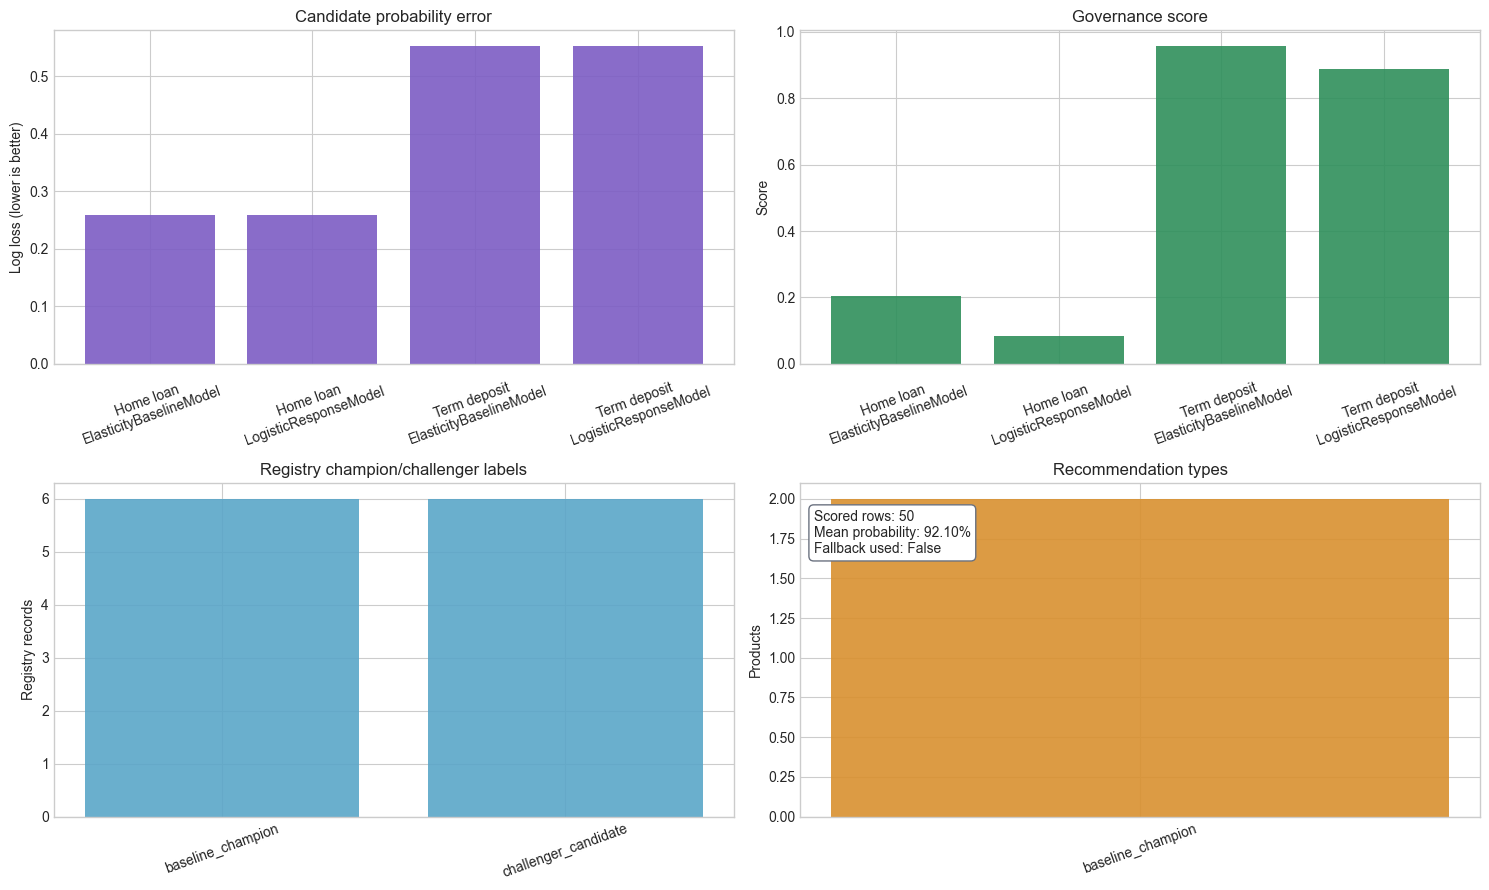

In [52]:
plot_governed_modelling_summary(
    agentic_candidate_summary,
    agentic_recommendations,
    agentic_registry,
    loan_score,
)


## Part 5: Optional Inputs And Next Steps
This final part covers optional competitor-rate inputs, experiment ideas, glossary terms, troubleshooting, and command-line equivalents.


### Optional Step 1: Run With Competitor Rate Inputs
This section is optional. The baseline notebook already has competitor assumptions in `configs/base.yaml`. This section only matters if you have generated a competitor-rate file under `data/processed/competitor_rates/latest.json`.


In [53]:
competitor_file = PROJECT_ROOT / "data" / "processed" / "competitor_rates" / "latest.json"
print(f"Competitor file exists: {competitor_file.exists()}")
print(competitor_file)

Competitor file exists: True
/Users/kevinchang/Documents/ai-bank-pricing-engine/data/processed/competitor_rates/latest.json


In [54]:
try:
    from balance_pricing_engine.competitor_rates.apply import apply_competitor_rates_to_config
    from balance_pricing_engine.competitor_rates.models import CompetitorRatesConfig
    from balance_pricing_engine.scenarios.runner import run_baseline_diagnostics

    competitor_config = config.competitor_rates or CompetitorRatesConfig()
    competitor_config = competitor_config.model_copy(
        update={"enabled": True, "source_file": str(competitor_file)}
    )
    config_with_competitor_rates = config.model_copy(update={"competitor_rates": competitor_config})
    config_with_competitor_rates = apply_competitor_rates_to_config(config_with_competitor_rates)
    diag_with_comp = run_baseline_diagnostics(config_with_competitor_rates)
    print("Competitor rates applied successfully.")
    display(build_scenario_comparison_table(diagnostics.best_result, diag_with_comp.best_result))
except Exception as e:
    print(f"Competitor rates not applied: {e}")
    print()
    print("To refresh competitor rates, run:")
    print("  python3 -m balance_pricing_engine.competitor_rates.cli fetch --output-dir data/processed/competitor_rates")
    print("Then re-run this cell.")


Competitor rates not applied: Competitor-rate file is stale: 210.2 hours old (max 48)

To refresh competitor rates, run:
  python3 -m balance_pricing_engine.competitor_rates.cli fetch --output-dir data/processed/competitor_rates
Then re-run this cell.


### Optional Step 2: Where To Experiment Next
The safest beginner workflow is:
1. Change one assumption at a time.
2. Rerun the baseline optimisation.
3. Compare the recommendation and objective.
4. If you are testing learned response models, rerun the response modelling and governed modelling sections.
5. Ask whether the direction makes business and model-risk sense.


### Reference: Beginner Glossary
- **Portfolio-level pricing:** one rate for the whole synthetic portfolio, not a personalized rate for each customer.
- **Home loan rate:** the interest rate charged on the lending product.
- **Term deposit rate:** the interest rate paid on the funding product.
- **Rate grid:** the list of candidate rates the optimiser tests.
- **Objective:** the value the optimiser is trying to maximise.
- **Expected loan volume:** loan balances expected to be accepted at a given home loan rate.
- **Expected deposit volume:** deposit balances expected to be placed at a given term deposit rate.
- **Funding shortfall:** the amount of required deposit funding not covered by expected deposits.
- **Boundary warning:** a signal that the chosen rate is at the edge of the tested range.
- **Sensitivity analysis:** rerunning the model under changed assumptions to see how stable the answer is.
- **AUC:** a model metric for ranking quality. Higher is better.
- **Calibration:** whether predicted probabilities line up with observed outcome rates.
- **Champion/challenger:** a governance pattern where the current trusted model remains champion while alternatives are evaluated as challengers.
- **Model registry:** a local audit trail of trained candidates, metrics, artifacts, and governance status.
- **Fallback model:** the transparent model used when a learned artifact is missing or not approved for scoring.


### Reference: Troubleshooting
#### `Running cells with 'Python 3.12.13' requires the ipykernel package`

VS Code/Jupyter is trying to use a Python interpreter that does not have notebook-kernel support installed. From the repo root, run:

```bash
/opt/homebrew/bin/python3.12 -m venv .venv
source .venv/bin/activate
python -m pip install --upgrade pip setuptools wheel
python -m pip install -e ".[dev]"
python -m ipykernel install --user --name ai-bank-pricing-engine-py312 --display-name "AI Bank Pricing Engine (Python 3.12)"
```

Then restart VS Code or Jupyter and select **AI Bank Pricing Engine (Python 3.12)** as the notebook kernel.

#### `ModuleNotFoundError: No module named 'balance_pricing_engine'`

Run this from the repo root:

```bash
python -m pip install -e ".[dev]"
```

Then restart the notebook kernel and rerun from the top.

#### `matplotlib is not installed`

Install the project with development dependencies in the same Python environment used by the notebook kernel:

```bash
python -m pip install -e ".[dev]"
```

If you use the included Jupyter kernel, select **AI Bank Pricing Engine (Python 3.12)**, restart the kernel, and rerun the plotting cells.

#### Governed modelling cells write files

That is expected. Training reports, model artifacts, and registry records are written under `data/outputs/agentic_notebook/`, which is ignored by git. Delete that folder if you want a clean rerun.

#### Results change after editing assumptions

That is expected. The project uses synthetic data and a fixed random seed. If you change the seed or assumptions, the optimal pricing decision may move.

#### Boundary warnings appear

Boundary warnings do not mean the code failed. They mean the best tested answer sits at the edge of the tested range. Consider widening the relevant rate grid or reviewing the elasticity and penalty assumptions.


### Reference: Command-Line Equivalents
Most important notebook steps map back to these scripts:

```bash
python3 examples/run_baseline.py
python3 examples/train_response_models.py
python3 examples/run_with_competitor_rates.py
```

The governed modelling section is currently demonstrated programmatically in this notebook. For the design direction behind it, see `docs/agentic_modelling_roadmap.md`.

Use the notebook when you want explanation and charts. Use the command line when you want a fast repeatable run.


## Final Beginner Checklist

After your first complete run, you should be able to answer these questions:

1. What home loan rate did the model recommend?
2. What term deposit rate did the model recommend?
3. Was there a funding shortfall?
4. Were there any final boundary warnings?
5. Which sensitivity cases changed the recommendation the most?
6. Did the learned response models pass calibration and rate-response checks?
7. Which governed candidate was recommended as champion or challenger?
8. Did scoring use a learned artifact or the fallback model?
9. Which assumption would you like to test next?

If you can answer those, you are using the notebook correctly.
